# DAU fell after an SDK release. Did player activity change, or did measurement break?

> **Fictional portfolio demonstration.** All data and incident details are synthetic. The results describe this simulation only, not a real game or business outcome.

## Decision
Diagnose an apparent drop in daily active users (DAU) after a staged analytics SDK release. Separate changes in true simulated activity from failures in event identity and delivery.

## Simulation design
The generator creates a stable player population with ordinary daily variation. After rollout, a subset of upgraded players has missing IDs on all their client events. It also injects retry duplicates and longer event delays. A separate truth table records the known active-user count by date and platform. This is an evaluation aid available only because the data are simulated; a real analyst would not have this oracle.

The rollout is staggered: Android starts on 12 May 2026 and iOS on 15 May 2026. Use event timestamps for activity date. The DAU proxy counts distinct non-null users with `app_open` or `session_start`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()
if not (BASE / 'data').exists() and (BASE / '8-mobile-sdk-metric-drop' / 'data').exists():
    BASE = BASE / '8-mobile-sdk-metric-drop'
(BASE / 'outputs').mkdir(exist_ok=True)
events = pd.read_csv(BASE / 'data/events.csv', parse_dates=['event_timestamp', 'received_timestamp'])
truth = pd.read_csv(BASE / 'data/simulation_truth.csv', parse_dates=['date'])
print(f'{len(events):,} event rows, {events.event_timestamp.min().date()} to {events.event_timestamp.max().date()}')
events.head()

97,599 event rows, 2026-05-01 to 2026-06-14


,event_id,user_id,event_name,event_timestamp,received_timestamp,platform,app_version,country,acquisition_channel
0,20260501_u00000_0,u00000,app_open,2026-05-01 19:35:39,2026-05-01 19:48:18.406484,Android,4.7.9,US,Organic
1,20260501_u00000_1,u00000,session_start,2026-05-01 19:40:39,2026-05-01 20:14:06.969249,Android,4.7.9,US,Organic
2,20260501_u00000_2,u00000,level_start,2026-05-01 19:45:39,2026-05-01 19:45:46.912455,Android,4.7.9,US,Organic
3,20260501_u00000_3,u00000,level_start,2026-05-01 19:51:39,2026-05-01 19:57:54.644099,Android,4.7.9,US,Organic
4,20260501_u00001_0,u00001,app_open,2026-05-01 20:21:26,2026-05-01 20:25:05.109892,Android,4.7.9,GB,Search Ads


## 1. Validate the data and define the metric
`user_id` blanks are expected in this simulation. Event IDs must remain unique, including retry rows. The dashboard-style DAU uses valid user IDs and qualifying activity events.

In [2]:
required = {'event_id','user_id','event_name','event_timestamp','received_timestamp','platform','app_version','country','acquisition_channel'}
assert required <= set(events.columns)
assert events.event_id.is_unique
assert (events.received_timestamp >= events.event_timestamp).all()
events['event_date'] = events.event_timestamp.dt.floor('D')
events['delay_hours'] = (events.received_timestamp - events.event_timestamp).dt.total_seconds() / 3600
events['is_retry'] = events.event_id.str.endswith('_retry')
activity = events[events.event_name.isin(['app_open','session_start'])]
dau = (activity.dropna(subset=['user_id']).groupby(['event_date','platform']).user_id.nunique().rename('observed_dau').reset_index())
dau.head()

,event_date,platform,observed_dau
0,2026-05-01,Android,439
1,2026-05-01,iOS,294
2,2026-05-02,Android,460
3,2026-05-02,iOS,294
4,2026-05-03,Android,464


## 2. Compare observed DAU with the simulation truth
The truth table is hidden ground truth for this generated example. It lets us measure the impact of identity loss. In a real incident, use an independent source (for example, server-side activity) rather than assuming client data are complete.

In [3]:
observed = dau.groupby('event_date').observed_dau.sum().rename('observed_dau').reset_index()
comparison = truth.merge(observed, left_on='date', right_on='event_date', how='left')
comparison['coverage'] = comparison.observed_dau / comparison.true_active_users
pre = comparison[comparison.date < '2026-05-12']
post = comparison[comparison.date >= '2026-05-15']
summary = pd.DataFrame({
    'period':['Before rollout','After both platforms rolled out'],
    'mean_true_dau':[pre.true_active_users.mean(),post.true_active_users.mean()],
    'mean_observed_dau':[pre.observed_dau.mean(),post.observed_dau.mean()],
    'mean_observed_coverage':[pre.coverage.mean(),post.coverage.mean()]
}).set_index('period').round(3)
summary

,mean_true_dau,mean_observed_dau,mean_observed_coverage
period,,,
Before rollout,741.182,741.182,1.000
After both platforms rolled out,736.226,678.000,0.921


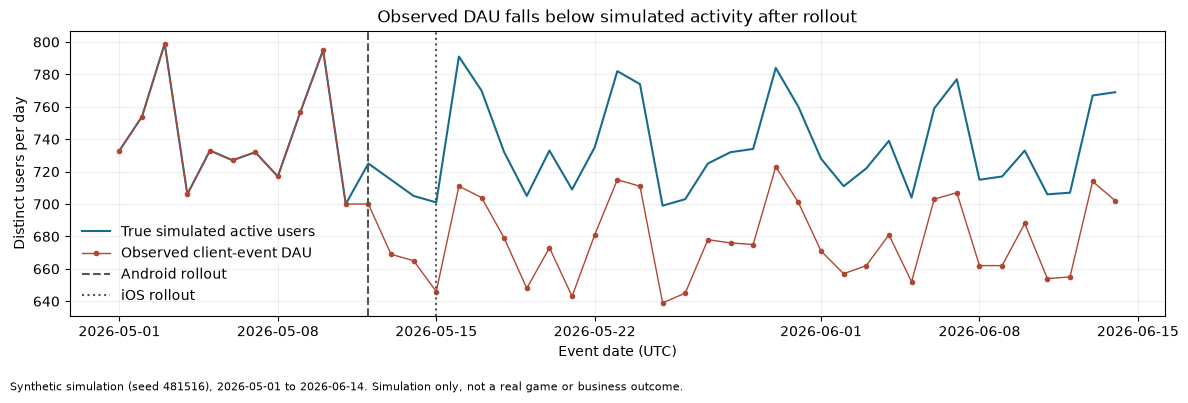

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(comparison.date, comparison.true_active_users, label='True simulated active users', color='#176b8c', linewidth=1.5)
ax.plot(comparison.date, comparison.observed_dau, label='Observed client-event DAU', color='#b14632', marker='.', linewidth=1)
ax.axvline(pd.Timestamp('2026-05-12'), color='#555555', linestyle='--', label='Android rollout')
ax.axvline(pd.Timestamp('2026-05-15'), color='#555555', linestyle=':', label='iOS rollout')
ax.set(title='Observed DAU falls below simulated activity after rollout', xlabel='Event date (UTC)', ylabel='Distinct users per day')
ax.grid(alpha=.2); ax.legend(frameon=False)
fig.text(.01, .01, 'Synthetic simulation (seed 481516), 2026-05-01 to 2026-06-14. Simulation only, not a real game or business outcome.', fontsize=8)
plt.tight_layout(rect=(0, .05, 1, 1))
fig.savefig(BASE / 'outputs' / 'observed_vs_true_dau.png', dpi=160)


## 3. Check event quality by date and app version
Missing IDs are simulated as a player-level problem after that player's platform rollout. Retry duplicates use a `_retry` suffix only because this generator controls the data. In production, use a documented idempotency key or a validated event fingerprint.

In [5]:
quality = events.groupby(['event_date','platform','app_version']).agg(
    event_rows=('event_id','size'),
    missing_id_share=('user_id',lambda s:s.isna().mean()),
    retry_share=('is_retry','mean'),
    p95_delay_hours=('delay_hours',lambda s:s.quantile(.95))
).reset_index()
quality.head()

,event_date,platform,app_version,event_rows,missing_id_share,retry_share,p95_delay_hours
0,2026-05-01,Android,4.7.9,1283,0.005456,0.0,0.531837
1,2026-05-01,iOS,4.7.8,855,0.003509,0.0,0.517134
2,2026-05-02,Android,4.7.9,1345,0.002230,0.0,0.534511
3,2026-05-02,iOS,4.7.8,865,0.006936,0.0,0.538055
4,2026-05-03,Android,4.7.9,1394,0.004304,0.0,0.575891


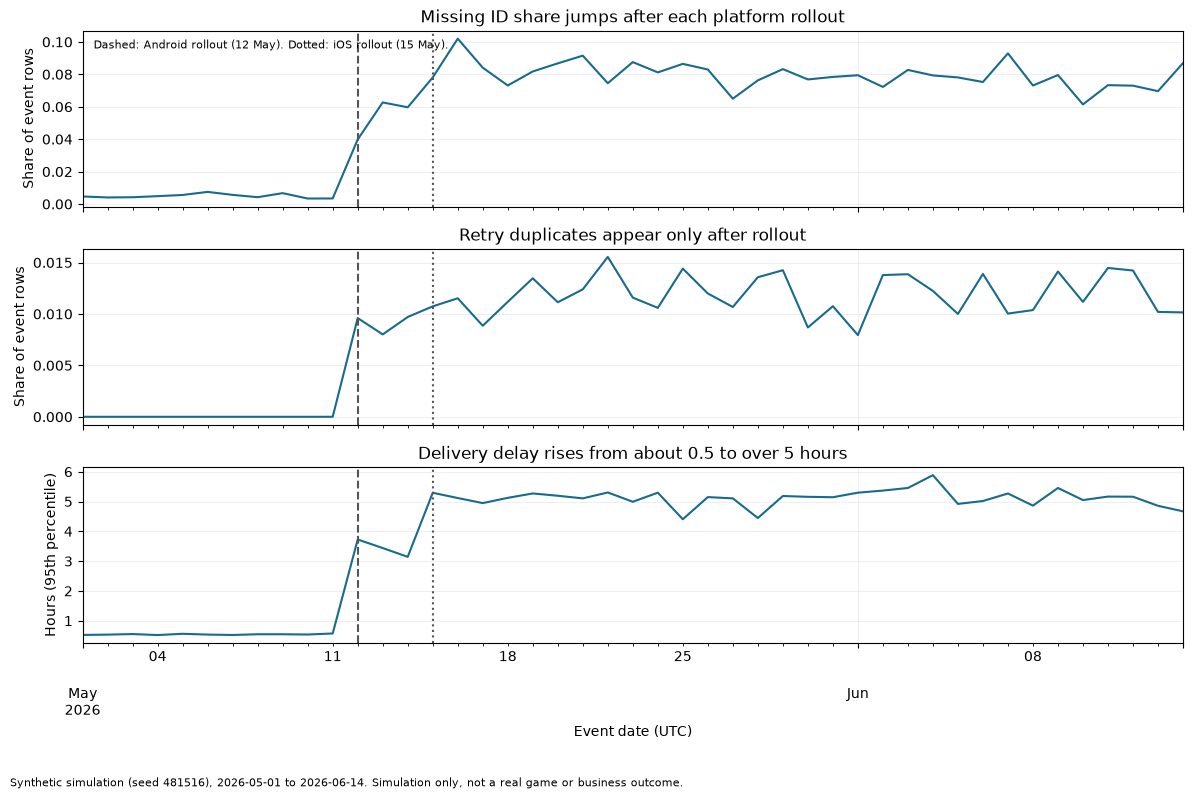

In [6]:
daily = events.groupby('event_date').agg(
    missing_id_share=('user_id',lambda s:s.isna().mean()),
    retry_share=('is_retry','mean'),
    p95_delay_hours=('delay_hours',lambda s:s.quantile(.95))
)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
panels = [
    ('missing_id_share', 'Missing ID share jumps after each platform rollout', 'Share of event rows'),
    ('retry_share', 'Retry duplicates appear only after rollout', 'Share of event rows'),
    ('p95_delay_hours', 'Delivery delay rises from about 0.5 to over 5 hours', 'Hours (95th percentile)'),
]
for (col, title, ylabel), ax in zip(panels, axes):
    daily[col].plot(ax=ax, color='#176b8c')
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(alpha=.2)
for ax in axes:
    ax.axvline(pd.Timestamp('2026-05-12'), color='#555555', linestyle='--')
    ax.axvline(pd.Timestamp('2026-05-15'), color='#555555', linestyle=':')
axes[0].text(.01, .95, 'Dashed: Android rollout (12 May). Dotted: iOS rollout (15 May).', transform=axes[0].transAxes, fontsize=8, va='top')
axes[-1].set_xlabel('Event date (UTC)')
fig.text(.01, .01, 'Synthetic simulation (seed 481516), 2026-05-01 to 2026-06-14. Simulation only, not a real game or business outcome.', fontsize=8)
plt.tight_layout(rect=(0, .05, 1, 1))
fig.savefig(BASE / 'outputs' / 'event_quality_diagnostics.png', dpi=160)


## 4. Locate the issue by platform and version
The staged rollout provides a useful diagnostic comparison, but it is not a randomized experiment. Differences by version are consistent with a measurement failure in this simulation; date alignment alone would not prove causation in a real product.

In [7]:
version_check = events.groupby(['platform','app_version']).agg(
    rows=('event_id','size'),
    missing_id_share=('user_id',lambda s:s.isna().mean()),
    retry_share=('is_retry','mean'),
    p95_delay_hours=('delay_hours',lambda s:s.quantile(.95))
).round(3)
version_check

rows  missing_id_share  retry_share  p95_delay_hours
platform app_version                                                       
Android  4.7.9        14186             0.005        0.000            0.545
         4.8.0        43732             0.080        0.012            5.205
iOS      4.7.8        12282             0.005        0.000            0.536
         4.8.0        27399             0.080        0.012            5.015

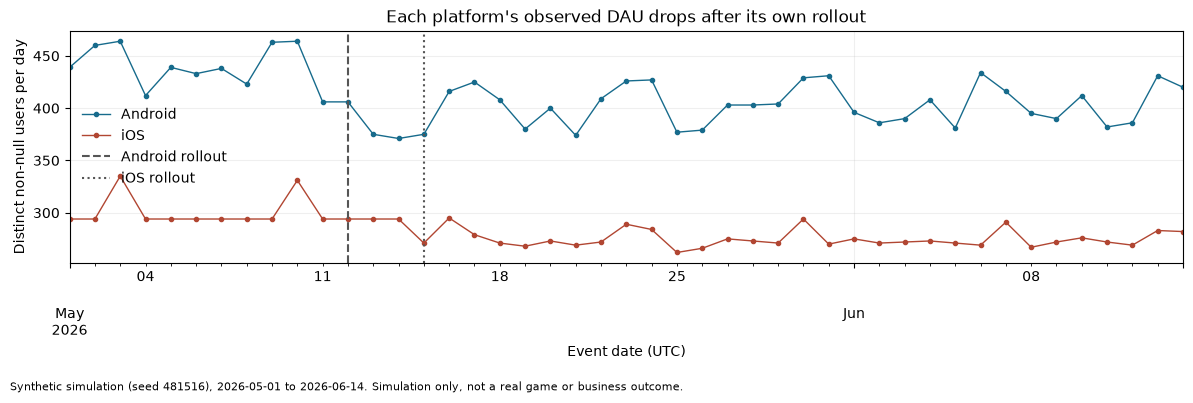

In [8]:
platform_dau = dau.pivot(index='event_date', columns='platform', values='observed_dau')
fig, ax = plt.subplots(figsize=(12, 4))
platform_dau.plot(ax=ax, marker='.', linewidth=1, color=['#176b8c', '#b14632'])
ax.axvline(pd.Timestamp('2026-05-12'), color='#555555', linestyle='--', label='Android rollout')
ax.axvline(pd.Timestamp('2026-05-15'), color='#555555', linestyle=':', label='iOS rollout')
ax.set_title("Each platform's observed DAU drops after its own rollout")
ax.set_xlabel('Event date (UTC)'); ax.set_ylabel('Distinct non-null users per day')
ax.grid(alpha=.2); ax.legend(frameon=False)
fig.text(.01, .01, 'Synthetic simulation (seed 481516), 2026-05-01 to 2026-06-14. Simulation only, not a real game or business outcome.', fontsize=8)
plt.tight_layout(rect=(0, .05, 1, 1))
fig.savefig(BASE / 'outputs' / 'observed_dau_by_platform.png', dpi=160)


## 5. Account for late-arriving events
Compare the final event-time metric with what would have been visible at day end and 24 hours after each event date ended. This is a simple snapshot simulation, not a full warehouse freshness model. Events received after a cutoff backfill historical DAU, so a slowly delivered pipeline can silently revise yesterday's numbers.


In [9]:
activity = activity.copy()
# Event date ends at D+1 00:00 UTC. Compare what is visible at day end and 24 hours later (D+2 00:00 UTC).
visible = activity[activity.user_id.notna()].copy()
visible['day_end_cutoff'] = visible.event_date + pd.Timedelta(days=1)
visible['snapshot_cutoff'] = visible.event_date + pd.Timedelta(days=2)
at_day_end = visible[visible.received_timestamp < visible.day_end_cutoff].groupby('event_date').user_id.nunique().rename('available_at_day_end')
available_24h = visible[visible.received_timestamp < visible.snapshot_cutoff].groupby('event_date').user_id.nunique().rename('available_after_24h')
latency_check = comparison.set_index('date')[['true_active_users','observed_dau']].join([at_day_end, available_24h])
latency_check[['available_at_day_end','available_after_24h']] = latency_check[['available_at_day_end','available_after_24h']].fillna(0)
for column in ('available_at_day_end', 'available_after_24h'):
    short = latency_check.observed_dau - latency_check[column]
    print(f'{column}: days short = {int((short > 0).sum())}, missing user-days = {int(short.sum())}, worst day = {int(short.max())}')
print(f'Maximum delivery delay in the sample: {events.delay_hours.max():.1f} hours')
latency_check.tail(10)


available_at_day_end: days short = 27, missing user-days = 40, worst day = 5
available_after_24h: days short = 0, missing user-days = 0, worst day = 0
Maximum delivery delay in the sample: 9.0 hours


,true_active_users,observed_dau,available_at_day_end,available_after_24h
date,,,,
2026-06-05,704,652,651,652
2026-06-06,759,703,702,703
2026-06-07,777,707,707,707
2026-06-08,715,662,661,662
2026-06-09,717,662,662,662
2026-06-10,733,688,687,688
2026-06-11,706,654,653,654
2026-06-12,707,655,655,655
2026-06-13,767,714,714,714


## Interpretation

- **In this simulation:** true active users remain near the designed baseline, while observed DAU falls after rollout because some upgraded players lose their identifiers. Event retries inflate raw event rows but do not inflate distinct-user DAU in this metric. Delivery delays leave day-end counts incomplete on 27 of 45 days (worst day: 5 users short), but every event in this sample arrives within 9.0 hours, so the 24-hour snapshot already equals the final event-time count.
- **Business conclusion:** treat the DAU dashboard as degraded; do not respond by changing UA budgets or product features until the event pipeline is checked. Validate ID completeness, retry handling, delivery lag, and server/client agreement by app version.
- **Limits:** the rollout is not randomized; there is no real backend data, spend table, or causal impact estimate. The simulation truth is available only because we generated the data. Do not report these numbers as real findings.